# Peak-retention EDA without loading the full dataset

**Start in a fresh Colab CPU runtime. Run this notebook instead of your old loading cells.**
Do not run `pd.read_parquet`, `pq.read_table`, or create full `casmi_train_df` / `casmi_val_df` first.
A 3 GB compressed file can require substantially more RAM after decoding.

This notebook reads only three columns in batches of 64 rows, disables parallel reading and read-ahead caching, and scans the whole file to obtain a uniform random sample of up to 20,000 spectra per split. Only compact peak-retention statistics are retained. It never accumulates batches or raw spectra. The statistics arrays use about 2 MB total; Arrow decoding buffers and the current batch require additional memory. A batch size is a row count, not a strict RAM cap: unusually large rows or Parquet pages can still need substantial memory.

**Split choice:** by default this creates a NEW reproducible 80/20 EDA partition from `inchikey14`. It keeps identical supplied identities together but does not reproduce your earlier random split or standardize chemical identities. Set `SPLIT_LOOKUP` from a saved molecule-level split if you need that exact comparison. Never reload the full spectra to reconstruct it. `inchikey14` must be a verified, consistently standardized identity.

The graph compares median and 10th-percentile summed-intensity retention at different encoder lengths. One input position is reserved for your ADDED precursor token; length 128 therefore permits 127 original peaks.


In [1]:
# Colab usually already includes these. This cell installs only if unavailable.
import importlib.util
import subprocess
import sys
needed = [p for p in ('pyarrow','numpy','pandas','matplotlib')
          if importlib.util.find_spec(p) is None]
if needed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *needed])
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:




from pathlib import Path
TRAIN_PATH = '/content/drive/MyDrive/Colab Notebooks/train.parquet'
KEY_COL = 'inchikey14'
BATCH_SIZE = 64
SAMPLE_PER_SPLIT = 20_000
LENGTHS = (32,64,128,256,512,1024)
SEED = 42

# Optional existing molecule split: {identity: 'Training' or 'Validation'}.
# Leave None for the clearly labelled new hash-grouped EDA partition.
SPLIT_LOOKUP = None
assert Path(TRAIN_PATH).is_file(), f'File not found: {TRAIN_PATH}'
import pyarrow.parquet as pq
with pq.ParquetFile(TRAIN_PATH, pre_buffer=False) as pf:
    print(f'{pf.metadata.num_rows:,} rows; {pf.metadata.num_row_groups} row groups')
    print('Columns:', pf.schema_arrow.names)
# Reading the footer above does not load the spectrum table.


2,539,608 rows; 21 row groups
Columns: ['ingest_lib', 'normalized_smiles', 'inchikey', 'inchikey14', 'molecular_formula', 'ionization_mode', 'instrument_type', 'adduct', 'adduct_orig', 'precursor_mz', 'precursor_error_ppm', 'ms2_mzs', 'ms2_normalized_intensities', 'num_peaks', 'base_peak_intensity', 'collision_energy_ev', 'collision_energy_orig', 'collision_energy_orig_units']


In [3]:
import hashlib
import json
from collections import Counter
import numpy as np


def retention_row(mz_value, intensity_value, lengths):
    """Return compact measurements plus an error reason; never store raw peaks."""
    try:
        def array(value):
            if isinstance(value, str):
                value = json.loads(value)
            return np.asarray(value, dtype=np.float64)
        mz, intensities = array(mz_value), array(intensity_value)
        if mz.ndim != 1 or intensities.ndim != 1:
            return None, 'not_1d'
        if len(mz) != len(intensities):
            return None, 'length_mismatch'
        if len(mz) == 0:
            return None, 'empty'
        if not np.all(np.isfinite(mz)) or np.any(mz <= 0):
            return None, 'invalid_mz'
        if not np.all(np.isfinite(intensities)) or np.any(intensities < 0):
            return None, 'invalid_intensity'
        maximum = intensities.max()
        if maximum <= 0:
            return None, 'all_zero'
        values = intensities / maximum
        n = len(values)
        limits = np.asarray(lengths, dtype=int) - 1
        k = min(n, int(limits.max()))
        selected = np.partition(values, n-k)[-k:]
        cumulative = np.cumsum(np.sort(selected)[::-1])
        ratios = cumulative[np.minimum(limits, n)-1] / values.sum()
        ratios = np.where(limits >= n, 1.0, np.clip(ratios, 0, 1))
        return (ratios.astype(np.float32), n), None
    except (ValueError, TypeError, OverflowError):
        return None, 'unparseable'


def split_for_key(key, validation_fraction=0.2, seed=42):
    # This stable assignment puts every occurrence of the SAME supplied identity
    # in the same EDA partition. It is not chemical identity standardization.
    digest = hashlib.blake2b(f'{seed}:{key}'.encode(), digest_size=8).digest()
    fraction = int.from_bytes(digest, 'big') / 2**64
    return 'Validation' if fraction < validation_fraction else 'Training'


def stream_retention(path, key_col='inchikey14', lengths=(32,64,128,256,512,1024),
                     batch_size=64, sample_per_split=20_000, seed=42,
                     validation_fraction=0.2, smoke_batches=None,
                     split_lookup=None, progress_every=100_000):
    """Scan all rows; uniform reservoir per split. Only sampled rows are audited.

    split_lookup: optional {identity: 'Training' or 'Validation'} for an EXISTING
    split. Every nonmissing identity must be mapped, or this raises an error.
    If omitted, create a NEW deterministic molecule-grouped EDA partition.
    smoke_batches: limit for a loading check ONLY; None scans the whole file.
    """
    import pyarrow.parquet as pq
    lengths = np.asarray(sorted(set(lengths)), dtype=int)
    if not len(lengths) or np.any(lengths < 2):
        raise ValueError('Input lengths must be >= 2 (one added precursor token).')
    if batch_size < 1 or sample_per_split < 1:
        raise ValueError('Batch size and sample capacity must be positive.')
    if not 0 < validation_fraction < 1:
        raise ValueError('validation_fraction must be between zero and one.')
    names = ('Training', 'Validation')
    groups = {}
    for i, name in enumerate(names):
        groups[name] = dict(seen=0, filled=0,
            ratios=np.full((sample_per_split, len(lengths)), np.nan, np.float32),
            counts=np.zeros(sample_per_split, np.int32),
            reasons=np.full(sample_per_split, '', dtype=object),
            rng=np.random.default_rng(seed+i))
    scanned, missing_ids, batches = 0, 0, 0
    # No whole-table read, DataFrame conversion, read-ahead cache, or parallel read.
    with pq.ParquetFile(path, pre_buffer=False) as pf:
        columns = [key_col, 'ms2_mzs', 'ms2_normalized_intensities']
        missing = set(columns) - set(pf.schema_arrow.names)
        if missing:
            raise ValueError(f'Missing columns: {sorted(missing)}. Available: {pf.schema_arrow.names}')
        expected_rows = pf.metadata.num_rows
        print(f'File: {expected_rows:,} rows; reading batches of {batch_size}.')
        for batch in pf.iter_batches(batch_size=batch_size, columns=columns,
                                     use_threads=False):
            ids, mzs, intensities = (batch.column(i) for i in range(3))
            for row in range(batch.num_rows):
                scanned += 1
                raw_key = ids[row].as_py()
                key = str(raw_key).strip() if raw_key is not None else ''
                if not key or key.lower() in ('nan', 'none', 'null'):
                    missing_ids += 1
                    continue
                if split_lookup is None:
                    name = split_for_key(key, validation_fraction, seed)
                else:
                    name = split_lookup.get(key)
                    if name not in names:
                        raise ValueError(f'Identity missing/invalid in split_lookup: {key!r}')
                group = groups[name]
                group['seen'] += 1
                # Algorithm R: all source rows in this split have equal final
                # inclusion probability, even when the file is sorted by source.
                if group['filled'] < sample_per_split:
                    slot = group['filled']
                    group['filled'] += 1
                else:
                    slot = int(group['rng'].integers(group['seen']))
                    if slot >= sample_per_split:
                        continue
                measurement, reason = retention_row(
                    mzs[row].as_py(), intensities[row].as_py(), lengths)
                if reason:
                    group['ratios'][slot] = np.nan
                    group['counts'][slot] = 0
                    group['reasons'][slot] = reason
                else:
                    group['ratios'][slot], group['counts'][slot] = measurement
                    group['reasons'][slot] = ''
            batches += 1
            if scanned % progress_every < batch.num_rows:
                print(f'Scanned {scanned:,} / {expected_rows:,} rows ...', flush=True)
            del ids, mzs, intensities, batch
            if smoke_batches is not None and batches >= smoke_batches:
                break
    for group in groups.values():
        size = group['filled']
        for field in ('ratios','counts','reasons'):
            group[field] = group[field][:size].copy()
        del group['rng']
    mode = 'Existing supplied split' if split_lookup is not None else 'NEW hash-grouped EDA split'
    result = dict(groups=groups, lengths=lengths, scanned=scanned,
                  missing_ids=missing_ids, expected_rows=expected_rows,
                  complete=(scanned == expected_rows), mode=mode)
    print(f'{mode}. Scanned {scanned:,} rows; missing identity: {missing_ids:,}.')
    for name, group in groups.items():
        reasons = Counter(r for r in group['reasons'] if r)
        print(f"{name}: {group['seen']:,} rows seen; {group['filled']:,} sampled; "
              f"{sum(reasons.values()):,} invalid sampled rows. {dict(reasons)}")
    return result


def plot_result(result):
    import pandas as pd
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(10,6), layout='constrained')
    lengths = result['lengths']
    summary = []
    plotted = 0
    for name, group in result['groups'].items():
        valid = np.all(np.isfinite(group['ratios']), axis=1)
        ratios, counts = group['ratios'][valid], group['counts'][valid]
        if not len(ratios):
            print(f'{name}: no valid sampled spectra; no curve.')
            continue
        p10, median = np.quantile(ratios, [.1, .5], axis=0) * 100
        line, = ax.plot(lengths, median, 'o-', label=f'{name}: median')
        ax.plot(lengths, p10, 's--', color=line.get_color(),
                label=f'{name}: 10th percentile')
        plotted += 1
        for j, length in enumerate(lengths):
            summary.append({'Split':name, 'Input length':int(length),
                'Measured peak limit':int(length-1), 'Valid sampled spectra':len(ratios),
                'Median retained (%)':median[j], 'P10 retained (%)':p10[j],
                'Spectra truncated (%)':100*np.mean(counts > length-1),
                'Invalid sampled spectra':int((~valid).sum())})
    if not plotted:
        plt.close(fig)
        raise ValueError('No valid sampled spectra. Check schema/identities/quality counts.')
    ax.axhline(95, color='gray', linestyle=':', label='95% reference')
    ax.axvline(128, color='gray', alpha=.4)
    ax.set_xscale('log', base=2)
    ax.set_xticks(lengths, [str(x) for x in lengths])
    ax.set_ylim(0,103)
    ax.set_xlabel('Encoder input length (includes one added precursor token)')
    ax.set_ylabel('Per-spectrum summed intensity retained (%)')
    status = 'Full-file reservoir sample' if result['complete'] else 'PARTIAL SCAN — loading check only'
    ax.set_title(f"{status}\n{result['mode']}")
    ax.grid(alpha=.2)
    ax.legend(fontsize=9, loc='lower right')
    return fig, pd.DataFrame(summary)


## First check that a small batch loads

This reads at most 128 rows. It is a loading check, not a representative EDA sample.
Watch Colab's system RAM indicator. If this step crashes, restart and reduce `BATCH_SIZE` to 8 or 1; unusual file pages/rows may require a higher-RAM runtime even with streaming. A GPU alone does not increase system RAM.


In [4]:
smoke = stream_retention(TRAIN_PATH, key_col=KEY_COL, lengths=LENGTHS,
    batch_size=BATCH_SIZE, sample_per_split=128, seed=SEED,
    smoke_batches=2, split_lookup=SPLIT_LOOKUP)
del smoke
import gc
gc.collect()


File: 2,539,608 rows; reading batches of 64.
NEW hash-grouped EDA split. Scanned 128 rows; missing identity: 0.
Training: 103 rows seen; 103 sampled; 0 invalid sampled rows. {}
Validation: 25 rows seen; 25 sampled; 0 invalid sampled rows. {}


43

## Scan the full file, keeping only sampled statistics

This can take time, especially when reading from Drive. Progress prints every 100,000 rows. Do not stop after the first batches and treat them as representative: files may be ordered by source or molecule. Reservoir sampling makes every eligible spectrum equally likely to appear in the final sample after the complete scan.

Missing identities are counted and excluded. Integrity checks apply **only to sampled rows**, not to every row scanned. Invalid sampled spectra are counted and excluded from curves. If invalidity is frequent, investigate it before drawing architecture conclusions.


File: 2,539,608 rows; reading batches of 64.
Scanned 100,032 / 2,539,608 rows ...
Scanned 200,000 / 2,539,608 rows ...
Scanned 300,032 / 2,539,608 rows ...
Scanned 400,000 / 2,539,608 rows ...
Scanned 500,032 / 2,539,608 rows ...
Scanned 600,000 / 2,539,608 rows ...
Scanned 700,032 / 2,539,608 rows ...
Scanned 800,000 / 2,539,608 rows ...
Scanned 900,032 / 2,539,608 rows ...
Scanned 1,000,000 / 2,539,608 rows ...
Scanned 1,100,032 / 2,539,608 rows ...
Scanned 1,200,000 / 2,539,608 rows ...
Scanned 1,300,032 / 2,539,608 rows ...
Scanned 1,400,000 / 2,539,608 rows ...
Scanned 1,500,032 / 2,539,608 rows ...
Scanned 1,600,000 / 2,539,608 rows ...
Scanned 1,700,032 / 2,539,608 rows ...
Scanned 1,800,000 / 2,539,608 rows ...
Scanned 1,900,032 / 2,539,608 rows ...
Scanned 2,000,000 / 2,539,608 rows ...
Scanned 2,100,032 / 2,539,608 rows ...
Scanned 2,200,000 / 2,539,608 rows ...
Scanned 2,300,032 / 2,539,608 rows ...
Scanned 2,400,000 / 2,539,608 rows ...
Scanned 2,500,032 / 2,539,608 rows ..

,Split,Input length,Measured peak limit,Valid sampled spectra,Median retained (%),P10 retained (%),Spectra truncated (%),Invalid sampled spectra
0,Training,32,31,20000,99.36,86.33,55.86,0
1,Training,64,63,20000,100.00,94.27,41.56,0
2,Training,128,127,20000,100.00,98.09,29.49,0
3,Training,256,255,20000,100.00,99.61,17.50,0
4,Training,512,511,20000,100.00,100.00,7.12,0
5,Training,1024,1023,20000,100.00,100.00,1.72,0
6,Validation,32,31,20000,99.38,86.59,56.00,0
7,Validation,64,63,20000,100.00,94.28,41.47,0
8,Validation,128,127,20000,100.00,98.04,29.22,0
9,Validation,256,255,20000,100.00,99.61,17.11,0


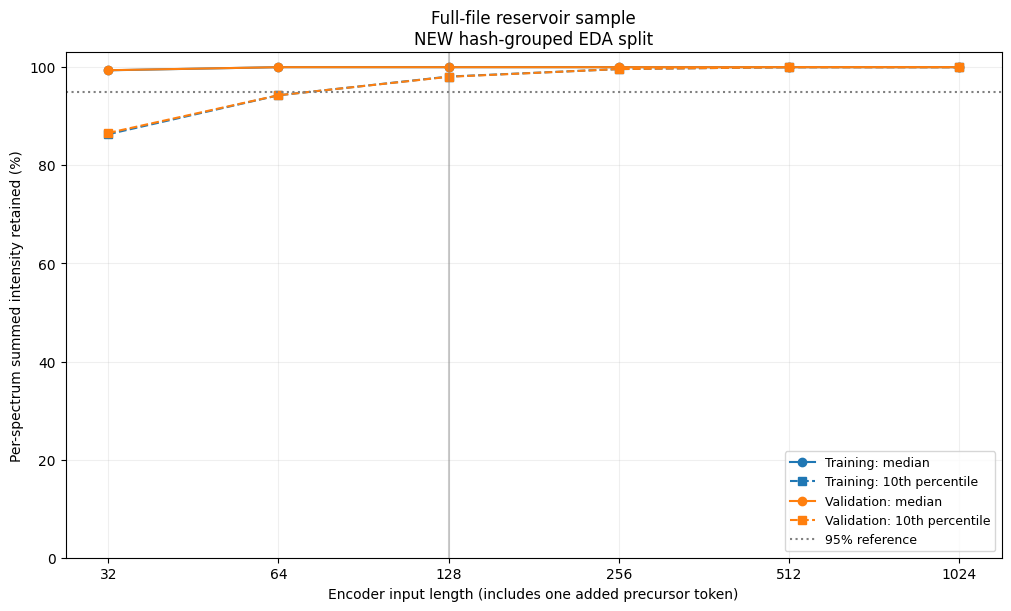

In [5]:
result = stream_retention(TRAIN_PATH, key_col=KEY_COL, lengths=LENGTHS,
    batch_size=BATCH_SIZE, sample_per_split=SAMPLE_PER_SPLIT,
    seed=SEED, split_lookup=SPLIT_LOOKUP)
fig, retention_summary = plot_result(result)
display(retention_summary.round(2))
import matplotlib.pyplot as plt
plt.show()


## Save the small outputs

These files preserve the results across runtime resets. They contain summary statistics, not the dataset.


In [6]:
from pathlib import Path
import json
OUTPUT_DIR = Path(TRAIN_PATH).parent / 'peak_retention_results'
OUTPUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUTPUT_DIR/'peak_retention.png', dpi=160, bbox_inches='tight')
retention_summary.to_csv(OUTPUT_DIR/'peak_retention_summary.csv', index=False)
report = {k:v for k,v in result.items() if k not in ('groups','lengths')}
report.update(batch_size=BATCH_SIZE, sample_per_split=SAMPLE_PER_SPLIT,
              seed=SEED, key_column=KEY_COL, input_lengths=list(LENGTHS))
report['sample_quality'] = {name:{'rows_seen':g['seen'], 'rows_sampled':g['filled'],
    'invalid_sampled':dict(Counter(r for r in g['reasons'] if r))}
    for name,g in result['groups'].items()}
(OUTPUT_DIR/'scan_report.json').write_text(json.dumps(report, indent=2))
print('Saved graph, CSV, and scan report to', OUTPUT_DIR)


Saved graph, CSV, and scan report to /content/drive/MyDrive/Colab Notebooks/peak_retention_results


## Interpretation and limits

- A low 10th-percentile curve exposes losses hidden by the median. Compare candidate lengths where curves flatten, then validate actual molecular prediction accuracy.
- Retained intensity is not retained chemical information. Weak diagnostic peaks may matter. A strong measured precursor peak can inflate the retained fraction; the artificial added precursor is excluded from this calculation.
- This mirrors strongest-peak selection without merging duplicate peaks, rounding m/z, deleting precursor peaks, or imposing a noise threshold. Those are separate experimental choices.
- Samples weight spectra equally; frequently measured molecules influence the results more. Rare sources/adducts need separate checks. This notebook does not validate SMILES or perform chemical consistency checks.
- New hash partitions are approximately 80/20 by identity, not guaranteed 80/20 by spectrum count. Preserve your original split through `SPLIT_LOOKUP` if required; do not compare these curves as if the partitions were identical to an earlier run.
- Results are reproducible for a fixed file row order, configuration, and NumPy environment. The entire dataset must be scanned for the final sample to cover all sources.

Reader reference: https://arrow.apache.org/docs/python/generated/pyarrow.parquet.ParquetFile.html

**Verification:** retention calculations, invalid-row handling, grouping and reservoir replacement were checked on synthetic cases. The full 3 GB dataset and Colab runtime were unavailable here, so actual peak memory and runtime are not measured.
